[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moiz-lakkadkutta/flyconn-course/blob/main/notebooks/01_meet_the_connectome.ipynb)

# 1. Meet the connectome

A **connectome** is a wiring diagram: every neuron in a nervous system, and how many synapses
each neuron makes onto every other. This one is the **male central nervous system of the fruit
fly *Drosophila melanogaster*** (MaleCNS v1.0, Berg et al. 2026): brain plus ventral nerve
cord, reconstructed from electron-microscope (EM) images.

**Learning goals.** By the end of this notebook you can

1. load a connectome's neuron table with pandas and say what one row means;
2. count neurons by class, side and cell type, and explain why "cell type" matters;
3. explain why every neurotransmitter label here is a **prediction**, and read its confidence;
4. find the neurons this course follows: taste neurons (`LB3*`) and a proboscis motor neuron
   (`MN9`).

**Time:** about 40 minutes. **You need:** basic Python (lists, functions). No install: in
Colab, run the setup cell and everything else downloads in seconds.

In [1]:
# @title Setup: run this cell first { display-mode: "form" }
import sys
import urllib.request
from pathlib import Path

if "google.colab" in sys.modules:
    %pip install -q flyconn==0.4.0 matplotlib
    pass
if not Path("course_utils.py").exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/moiz-lakkadkutta/flyconn-course/main/notebooks/course_utils.py",
        "course_utils.py",
    )

import matplotlib.pyplot as plt
import pandas as pd

import course_utils as cu

pd.set_option("display.max_rows", 20)

## 1. One row per neuron

Start with the **census**: one row for each of the neurons in the whole MaleCNS, with the
annotations the reconstruction team assigned. It has no connections yet; those come in
notebook 2.

In [2]:
census = cu.load_census()
print(f"{len(census):,} neurons, {census.shape[1]} columns")
census.head()

166,700 neurons, 11 columns


,neuron_id,super_class,cell_class,cell_type,side,nt_pred,nt_known,nt_conf,dimorphism,input_synapses_total,output_synapses_total
0,10001,descending,NaN,DNp01,right,acetylcholine,NaN,0.500,NaN,18582,4491
1,10002,visual_projection,NaN,OCG01d,left,acetylcholine,NaN,0.956,NaN,709,9165
2,10003,visual_centrifugal,NaN,VCH,right,gaba,gaba,0.879,NaN,27014,30020
3,10005,central_brain_intrinsic,NaN,AOTU019,right,gaba,gaba,0.835,NaN,31981,23423
4,10006,visual_projection,NaN,VS,left,acetylcholine,acetylcholine,0.904,NaN,20321,2175


The columns you will use most:

| column | meaning |
|---|---|
| `neuron_id` | the neuron's body ID in this dataset (unique within MaleCNS v1.0 only) |
| `super_class` | broad category: sensory, motor, intrinsic to a region, descending (brain to nerve cord), ascending (nerve cord to brain), ... |
| `cell_class`, `cell_type` | finer groupings; a cell type is a set of neurons that look alike and connect alike |
| `side` | left or right side of the body |
| `nt_pred`, `nt_conf` | **predicted** neurotransmitter and the classifier's confidence |
| `input_synapses_total`, `output_synapses_total` | how many synapses the neuron receives and makes |

## 2. What kinds of neurons are there?

In [3]:
by_class = census["super_class"].value_counts()
assert by_class["optic_lobe_intrinsic"] > len(census) / 2  # claim in the text below
by_class

super_class
optic_lobe_intrinsic            89403
central_brain_intrinsic         32164
sensory                         17336
ventral_nerve_cord_intrinsic    13161
visual_projection                9201
                                ...  
efferent_ascending                  8
efferent_descending                 4
visual_projection_tbc               2
sensory_ascending_tbc               2
descending_neuron_tbc               2
Name: count, Length: 22, dtype: int64

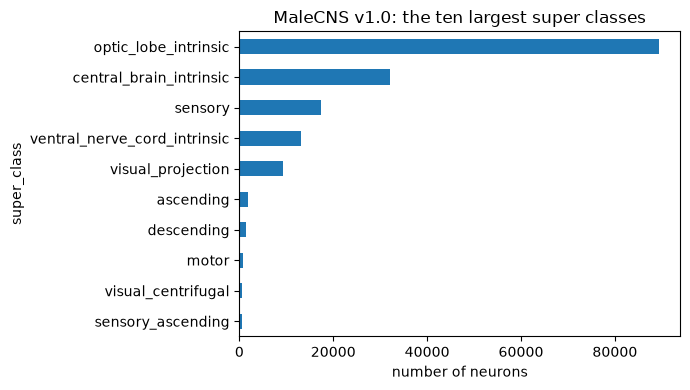

In [4]:
ax = by_class.head(10).iloc[::-1].plot.barh(figsize=(7, 4))
ax.set_xlabel("number of neurons")
ax.set_title("MaleCNS v1.0: the ten largest super classes")
plt.tight_layout()

More than half of all neurons sit in the optic lobes, the visual system. A fly's brain is, by
head count, mostly eyes.

Most neurons come in **left/right pairs**. Check:

In [5]:
census["side"].value_counts(dropna=False)

side
right     74235
left      74070
NaN       18003
center      392
Name: count, dtype: int64

## 3. Cell types

Studying 166,700 individual neurons is hopeless. Neuroscientists group them into **cell
types**: neurons with the same shape, position and connections. Many types are a single
left/right pair; some have thousands of members.

In [6]:
type_sizes = census["cell_type"].value_counts()
print(f"{type_sizes.size:,} cell types; {census['cell_type'].isna().sum():,} neurons have no type")
print(f"types with exactly 2 neurons: {(type_sizes == 2).sum():,}")
type_sizes.head(5)

11,751 cell types; 2,194 neurons have no type
types with exactly 2 neurons: 5,357


cell_type
R1-R6    3377
Tm3      2054
T3       1940
T2a      1872
L5       1787
Name: count, dtype: int64

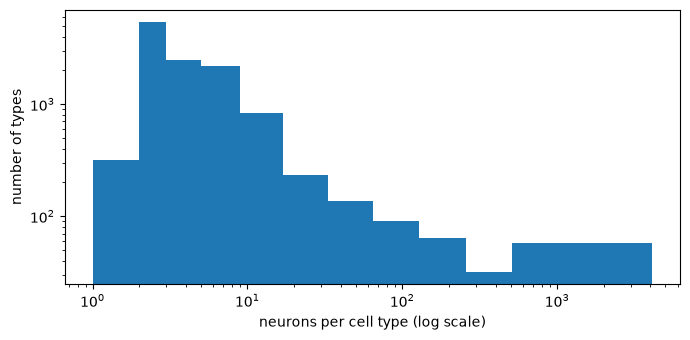

In [7]:
ax = type_sizes.plot.hist(
    bins=[1, 2, 3, 5, 9, 17, 33, 65, 129, 257, 513, 4096], log=True, figsize=(7, 3.5)
)
ax.set_xscale("log")
ax.set_xlabel("neurons per cell type (log scale)")
ax.set_ylabel("number of types")
plt.tight_layout()

The biggest types (`R1-R6`, `Tm3`, `T3`) are repeated once per facet of the compound eye.

## 4. Transmitters: measured, predicted, or combined?

A synapse excites or inhibits its target depending on the **neurotransmitter** it releases.
EM images show synapses but not which chemical they release. A machine-learning classifier
looks at each synapse in the images and votes for one of eight transmitters (Eckstein et al.
2024).

In this dataset, `nt_pred` is a **consensus label** built in three steps:

1. if experiments have measured the type's transmitter, use that (`nt_known` is then filled);
2. otherwise, use the classifier's vote pooled over all neurons of the cell type;
3. otherwise, use the neuron's own vote.

`nt_conf` is the classifier's confidence in the winning label.

> **Honesty label.** Unless `nt_known` is filled, a transmitter in this course is a
> **prediction**, not a measurement.

In [8]:
print(f"measured (nt_known filled): {census['nt_known'].notna().mean():.0%} of neurons")
census["nt_pred"].value_counts(dropna=False)

measured (nt_known filled): 51% of neurons


nt_pred
acetylcholine    103720
glutamate         29302
gaba              22069
histamine          7891
NaN                3177
dopamine            392
octopamine          101
serotonin            48
Name: count, dtype: int64

median confidence: 0.94


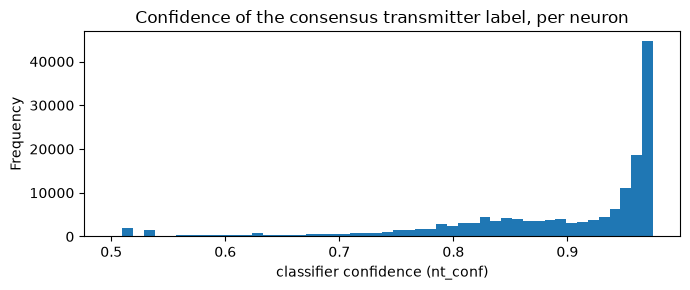

In [9]:
ax = census["nt_conf"].plot.hist(bins=50, figsize=(7, 3))
ax.set_xlabel("classifier confidence (nt_conf)")
ax.set_title("Confidence of the consensus transmitter label, per neuron")
plt.tight_layout()
print(f"median confidence: {census['nt_conf'].median():.2f}")

Most labels are confident. But a confident classifier can still be wrong, so test it on a
case where you know the answer. **Kenyon cells** (`KC*`, in the mushroom body, a learning
centre) release acetylcholine. Their transmitter is not in `nt_known` here, so their label
comes from step 2.

The teaching subset also stores the classifier's raw output for each neuron: `nt_p_*`, the
probability of each transmitter averaged over the neuron's synapses. Compare the consensus
label with each neuron's own top vote.

In [10]:
store = cu.open_store()
neurons = store.neurons()
nt_cols = [c for c in neurons.columns if c.startswith("nt_p_")]
neurons["nt_own_vote"] = (
    neurons[nt_cols]
    .fillna(0)
    .idxmax(axis=1)
    .str.removeprefix("nt_p_")
    .where(neurons[nt_cols].notna().any(axis=1))
)
kc = neurons[neurons["cell_type"].fillna("").str.startswith("KC")]
print(f"{len(kc)} Kenyon cells in the teaching subset")
print("consensus label (nt_pred):", kc["nt_pred"].value_counts().to_dict())
print("each neuron's own vote:   ", kc["nt_own_vote"].value_counts().to_dict())
assert (kc["nt_own_vote"] == "dopamine").mean() > 0.9  # claim in the text below

1023 Kenyon cells in the teaching subset
consensus label (nt_pred): {'acetylcholine': 1023}
each neuron's own vote:    {'dopamine': 1022, 'acetylcholine': 1}


Neuron by neuron, the classifier calls nearly every Kenyon cell dopaminergic, which is
wrong. The consensus label is right only because step 2 pooled the votes per cell type.
(Eckstein et al. report the same misprediction for Kenyon cells.) Lesson: the label you see
depends on *how* predictions were combined, and a high confidence is not a guarantee.

## 5. The cast of this course

The course follows one circuit: from **taste neurons on the fly's mouthparts** to the **motor
neuron that extends the proboscis** (the fly's tongue) so it can feed.

- `LB3a`–`LB3d`: gustatory receptor neurons (GRNs) of the labellum. In MaleCNS some respond to
  sugar and some to water; the dataset does not say which is which.
- `MN9`: a motor neuron for proboscis extension.

The teaching subset holds these neurons, every neuron they connect to directly, and their
connections. `cu.about` says exactly what it contains and how to cite it.

In [11]:
cu.about(store)

Dataset: malecns@1.0 (CC-BY-4.0), teaching subset 'malecns-1.0-gustatory'
  LB3* labellar GRNs, MN9, every neuron receiving >= 1 synapse from LB3* and every neuron sending >= 1 synapse to MN9 (focus); all edges with a focus neuron at either end; neurons = focus plus all their partners.
  edges: 502,095, focus_neurons: 953, neurons: 46,108, synapses: 3,878,833
  Edge threshold in the source: {'minconf': 0.5, 'pair_min_synapses': 1}
  Built with flyconn 0.4.0 on 2026-10-24
Cite:
- Berg S, Beckett IR, Costa M, Schlegel P, Januszewski M, et al. Sexual dimorphism in the complete Drosophila male central nervous system connectome. Cell 189(18):5504-5526.e15 (2026). doi:10.1016/j.cell.2026.08.015
NT = predicted by a classifier from EM images, not measured.


In [12]:
cast = neurons[neurons["cell_type"].fillna("").str.match(r"^(LB3|MN9$)")]
cast.groupby("cell_type").agg(
    neurons=("neuron_id", "size"),
    predicted_nt=("nt_pred", lambda s: ", ".join(sorted(s.dropna().unique())) or "none"),
    median_inputs=("input_synapses_total", "median"),
)

,neurons,predicted_nt,median_inputs
cell_type,,,
LB3,1,none,2.0
LB3a,17,acetylcholine,149.0
LB3b,11,acetylcholine,254.0
LB3c,23,acetylcholine,255.0
LB3d,26,acetylcholine,169.0
MN9,2,acetylcholine,3495.5


Notice the two `MN9` neurons. Same cell type, but one receives about ten times more synapses
than the other:

In [13]:
neurons.loc[
    neurons["cell_type"] == "MN9",
    ["neuron_id", "side", "nt_pred", "nt_conf", "input_synapses_total"],
]

,neuron_id,side,nt_pred,nt_conf,input_synapses_total
273,10331,left,acetylcholine,0.538602,6358
4740,16949,right,acetylcholine,0.573108,633


Possible reasons include biology, a part of one neuron that was harder to reconstruct, or
where the neuron's branches lie relative to the imaged volume. The connectome alone does not
tell you which. Keep this in mind in notebook 2: a number from a single neuron can mislead.

## Exercises

Try each one before opening the solution. In Colab, the solution cell's code is hidden;
double-click it to show the code.

**Exercise 1.** How many neurons are `motor` neurons, and what fraction of all neurons is that?

In [14]:
# your code here

In [15]:
# @title Solution 1 { display-mode: "form" }
n_motor = (census["super_class"] == "motor").sum()
print(f"{n_motor} motor neurons, {n_motor / len(census):.2%} of all neurons")

815 motor neurons, 0.49% of all neurons


**Exercise 2.** Which super class has the most *different* cell types (not the most neurons)?
Hint: `groupby(...)["cell_type"].nunique()`.

In [16]:
# your code here

In [17]:
# @title Solution 2 { display-mode: "form" }
census.groupby("super_class")["cell_type"].nunique().sort_values(ascending=False).head(5)

super_class
central_brain_intrinsic         6605
ventral_nerve_cord_intrinsic    2799
ascending                        567
descending                       480
visual_projection                346
Name: cell_type, dtype: int64

**Exercise 3.** For neurons in the teaching subset with a measured transmitter (`nt_known`),
how often does the neuron's own classifier vote (`nt_own_vote`) agree with it? Which
transmitter does worst? Then think: why might this agreement *overestimate* how well the
classifier does on neurons whose transmitter nobody has measured?

In [18]:
# your code here

In [19]:
# @title Solution 3 { display-mode: "form" }
both = neurons.dropna(subset=["nt_own_vote", "nt_known"])
both = both.assign(agree=both["nt_own_vote"] == both["nt_known"])
print(f"{len(both):,} neurons with both; agreement {both['agree'].mean():.1%}")
print(both.groupby("nt_known")["agree"].agg(["size", "mean"]).sort_values("mean"))
print(
    "Why it may overestimate: neurons of known transmitter are the ones classifiers are "
    "typically trained and tuned on, so they are not an independent test; and they are a "
    "biased sample (well-studied types). The Kenyon cells above had no measured label and "
    "were mispredicted."
)

16,446 neurons with both; agreement 99.4%
                size      mean
nt_known                      
histamine         13  0.846154
dopamine         218  0.986239
glutamate       1527  0.990832
gaba            4542  0.992955
acetylcholine  10070  0.994638
octopamine        37  1.000000
serotonin         39  1.000000
Why it may overestimate: neurons of known transmitter are the ones classifiers are typically trained and tuned on, so they are not an independent test; and they are a biased sample (well-studied types). The Kenyon cells above had no measured label and were mispredicted.


## Summary

- The neuron table has one row per neuron; cell types group neurons that look and connect
  alike.
- Transmitters are classifier **predictions** unless `nt_known` says otherwise, and how the
  predictions are combined changes the label (Kenyon cells).
- The same cell type can show very different numbers in different neurons.

**Next:** notebook 2, *Who talks to whom*, adds the connections and shows how the answer to
"are these two neurons connected?" depends on a threshold you choose.

*Data: MaleCNS v1.0, Berg et al. 2026, Cell, doi:10.1016/j.cell.2026.08.015 (CC BY 4.0), via
[flyconn](https://github.com/moiz-lakkadkutta/flyconn). Course text CC BY 4.0, code
Apache-2.0.*